# SpaceGuard AI — ML Phase 3A
## Preprocessing & Temporal Feature Engineering Research Notebook

> **Scope:** RESEARCH & PREPROCESSING ONLY.  
> **Rule:** **NO MACHINE LEARNING MODELS ARE TRAINED IN THIS NOTEBOOK.**  
> **Datasets:** NASA SMAP & MSL Telemanom Benchmark (`ml-service/data/raw/nasa_smap_msl/`).  
> **Goal:** Transform raw spacecraft telemetry into reproducible, leakage-safe, model-ready feature sets and candidate sliding window tensors.


### 1. Environment & Modular Imports
Import the research framework modules created in `ml-service/research/`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure ml-service root is in sys.path
ml_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ml_root) not in sys.path:
    sys.path.insert(0, str(ml_root))

from research.config import load_research_config
from research.dataset.loader import DatasetLoader
from research.dataset.validator import DatasetValidator
from research.preprocessing.variance import VarianceFilter
from research.preprocessing.classifier import ChannelClassifier
from research.preprocessing.scalers import ContinuousTransformer
from research.features.temporal import DeltaFeatures, RollingFeatures, EMAFeatures
from research.features.command import CommandInteractionFeatures
from research.features.pipeline import FeaturePipeline
from research.windowing.builder import WindowBuilder
from research.windowing.labeling import WindowLabeler

config = load_research_config()
print("Loaded Phase 3A Research Configuration successfully.")


Loaded Phase 3A Research Configuration successfully.


### 2. Dataset Loading & Integrity Validation
Load both MSL and SMAP benchmarks and verify zero NaNs, zero Infs, correct shapes, and label alignments.

In [2]:
loader = DatasetLoader()

msl_report = DatasetValidator.validate_mission(loader, "MSL")
smap_report = DatasetValidator.validate_mission(loader, "SMAP")

validation_summary = pd.DataFrame([
    {
        "Mission": msl_report.mission,
        "Train Shape": str(msl_report.train_shape),
        "Test Shape": str(msl_report.test_shape),
        "Test Label Shape": str(msl_report.test_label_shape),
        "Train NaNs": msl_report.train_nans,
        "Test NaNs": msl_report.test_nans,
        "Train Infs": msl_report.train_infs,
        "Test Infs": msl_report.test_infs,
        "Labels Match": msl_report.label_length_matches,
        "Is Valid": msl_report.is_valid,
    },
    {
        "Mission": smap_report.mission,
        "Train Shape": str(smap_report.train_shape),
        "Test Shape": str(smap_report.test_shape),
        "Test Label Shape": str(smap_report.test_label_shape),
        "Train NaNs": smap_report.train_nans,
        "Test NaNs": smap_report.test_nans,
        "Train Infs": smap_report.train_infs,
        "Test Infs": smap_report.test_infs,
        "Labels Match": smap_report.label_length_matches,
        "Is Valid": smap_report.is_valid,
    }
])
display(validation_summary)


,Mission,Train Shape,Test Shape,Test Label Shape,Train NaNs,Test NaNs,Train Infs,Test Infs,Labels Match,Is Valid
0,MSL,"(58317, 55)","(73729, 55)","(73729,)",0,0,0,0,True,True
1,SMAP,"(135183, 25)","(427617, 25)","(427617,)",0,0,0,0,True,True


### 3. Zero-Variance Channel Filtering (Training-Derived)
Filter channels with variance $< 10^{-8}$ calculated strictly on training data.

In [3]:
msl_train, msl_test = loader.load_mission("MSL")
smap_train, smap_test = loader.load_mission("SMAP")

var_filter_msl = VarianceFilter(threshold=1e-8)
var_filter_msl.fit(msl_train.data, split_name="train")

var_filter_smap = VarianceFilter(threshold=1e-8)
var_filter_smap.fit(smap_train.data, split_name="train")

var_table = pd.DataFrame([
    {
        "Mission": "MSL",
        "Original Channels": len(var_filter_msl.variances_),
        "Retained Channels": len(var_filter_msl.retained_indices_),
        "Removed Channels": len(var_filter_msl.removed_indices_),
        "Removed Indices": str(var_filter_msl.removed_indices_),
    },
    {
        "Mission": "SMAP",
        "Original Channels": len(var_filter_smap.variances_),
        "Retained Channels": len(var_filter_smap.retained_indices_),
        "Removed Channels": len(var_filter_smap.removed_indices_),
        "Removed Indices": str(var_filter_smap.removed_indices_),
    }
])
display(var_table)

X_train_msl_var = var_filter_msl.transform(msl_train.data)
X_test_msl_var = var_filter_msl.transform(msl_test.data)

X_train_smap_var = var_filter_smap.transform(smap_train.data)
X_test_smap_var = var_filter_smap.transform(smap_test.data)


,Mission,Original Channels,Retained Channels,Removed Channels,Removed Indices
0,MSL,55,33,22,"[1, 4, 8, 10, 18, 21, 22, 24, 25, 26, 30, 32, ..."
1,SMAP,25,24,1,[16]


### 4. Channel Classification (Continuous vs Discrete / Commands)
Classify channels deterministically into continuous, discrete/binary, and mixed categories.

In [4]:
class_msl = ChannelClassifier.classify(X_train_msl_var, continuous_indices=[0])
class_smap = ChannelClassifier.classify(X_train_smap_var, continuous_indices=[0])

class_df = pd.DataFrame([
    {
        "Mission": "MSL (Retained)",
        "Total Filtered Channels": X_train_msl_var.shape[1],
        "Continuous Count": len(class_msl.continuous_channels),
        "Discrete/Command Count": len(class_msl.discrete_channels),
        "Mixed Count": len(class_msl.mixed_channels),
    },
    {
        "Mission": "SMAP (Retained)",
        "Total Filtered Channels": X_train_smap_var.shape[1],
        "Continuous Count": len(class_smap.continuous_channels),
        "Discrete/Command Count": len(class_smap.discrete_channels),
        "Mixed Count": len(class_smap.mixed_channels),
    }
])
display(class_df)


,Mission,Total Filtered Channels,Continuous Count,Discrete/Command Count,Mixed Count
0,MSL (Retained),33,1,32,0
1,SMAP (Retained),24,1,23,0


### 5. Continuous Preprocessing Comparison
Compare candidate transformations (`passthrough`, `robust`, `minmax`) on Channel 0, fitted strictly on training data.

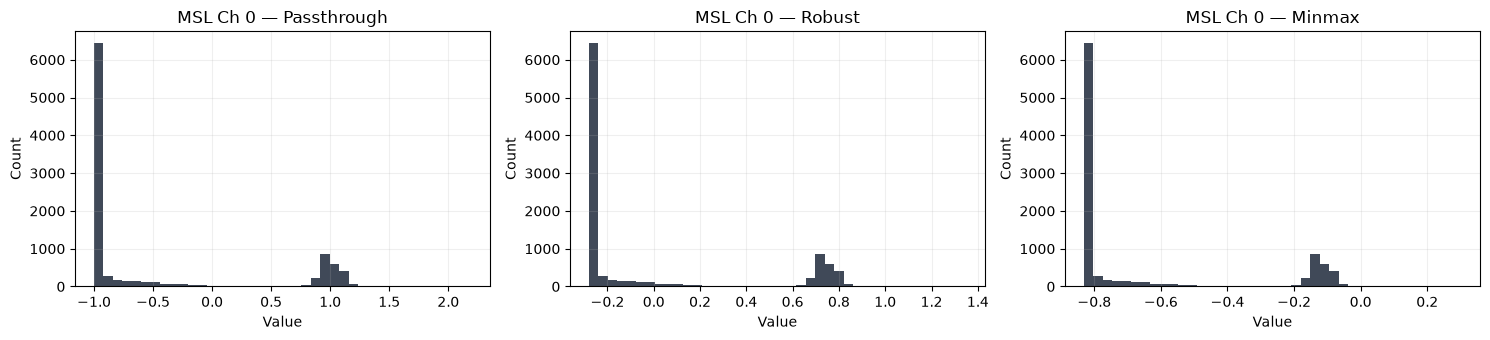

In [5]:
scalers = {}
for s_type in ["passthrough", "robust", "minmax"]:
    sc = ContinuousTransformer(scaler_type=s_type, mission="MSL")
    sc.fit(X_train_msl_var, continuous_channels=[0], split_name="train")
    scalers[s_type] = sc.transform(X_train_msl_var)[:, 0]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (s_name, s_vals) in zip(axes, scalers.items()):
    ax.hist(s_vals[:10000], bins=40, color="#1e293b", edgecolor="none", alpha=0.85)
    ax.set_title(f"MSL Ch 0 — {s_name.capitalize()}")
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 6. Discrete / Command Channel Analysis
Inspect command activation rates between nominal training and incident-rich test sets.

In [6]:
msl_cmd_train = np.mean(X_train_msl_var[:, 1:] != 0.0, axis=0)
msl_cmd_test = np.mean(X_test_msl_var[:, 1:] != 0.0, axis=0)

cmd_comp_df = pd.DataFrame({
    "Channel_Idx": list(range(1, len(msl_cmd_train) + 1)),
    "Train_Activation_Rate": np.round(msl_cmd_train, 4),
    "Test_Activation_Rate": np.round(msl_cmd_test, 4),
    "Activation_Shift": np.round(msl_cmd_test - msl_cmd_train, 4),
})
print("Top 10 Command Channels with Highest Test-Train Activation Shifts (MSL):")
display(cmd_comp_df.sort_values(by="Activation_Shift", ascending=False).head(10))


Top 10 Command Channels with Highest Test-Train Activation Shifts (MSL):


,Channel_Idx,Train_Activation_Rate,Test_Activation_Rate,Activation_Shift
27,28,0.0091,0.0109,0.0018
7,8,0.0130,0.0141,0.0010
11,12,0.0001,0.0008,0.0008
30,31,0.0008,0.0015,0.0007
10,11,0.0000,0.0006,0.0006
31,32,0.0012,0.0017,0.0005
19,20,0.0002,0.0007,0.0005
6,7,0.0291,0.0296,0.0005
16,17,0.0142,0.0145,0.0003
25,26,0.0001,0.0002,0.0001


### 7. Temporal & Command Feature Engineering
Extract causal first-order deltas, rolling statistics (10, 30, 100), EMAs (10, 30, 100), and command interaction features.

In [7]:
# Scaled arrays using default robust scaler
scaler_msl = ContinuousTransformer(scaler_type="robust", mission="MSL")
scaler_msl.fit(X_train_msl_var, continuous_channels=[0], split_name="train")
X_train_msl_scaled = scaler_msl.transform(X_train_msl_var)
X_test_msl_scaled = scaler_msl.transform(X_test_msl_var)

pipeline_msl = FeaturePipeline(
    mission="MSL",
    delta_orders=[1],
    rolling_windows=[10, 30, 100],
    rolling_metrics=["mean", "std", "min", "max"],
    ema_spans=[10, 30, 100],
    ema_divergences=[(10, 30), (30, 100)],
    include_commands=True,
)

X_train_msl_feat, msl_schema = pipeline_msl.transform(X_train_msl_scaled, continuous_channel_idx=0)
X_test_msl_feat, _ = pipeline_msl.transform(X_test_msl_scaled, continuous_channel_idx=0)

feature_counts = {
    "Base Continuous": 1,
    "Delta Features": 1,
    "Rolling Features (3 windows x 4 metrics)": 12,
    "EMA Features & Divergences": 5,
    "Command Interaction Features": 3,
    "Native Discrete Commands": X_train_msl_scaled.shape[1] - 1,
    "Total Engineered Dimensionality": X_train_msl_feat.shape[1],
}

display(pd.DataFrame(list(feature_counts.items()), columns=["Feature Group", "Count"]))


,Feature Group,Count
0,Base Continuous,1
1,Delta Features,1
2,Rolling Features (3 windows x 4 metrics),12
3,EMA Features & Divergences,5
4,Command Interaction Features,3
5,Native Discrete Commands,32
6,Total Engineered Dimensionality,54


### 8. Feature Trajectory Visualization
Visualize continuous telemetry alongside its derived delta, rolling mean, and EMA features over a representative sample interval.

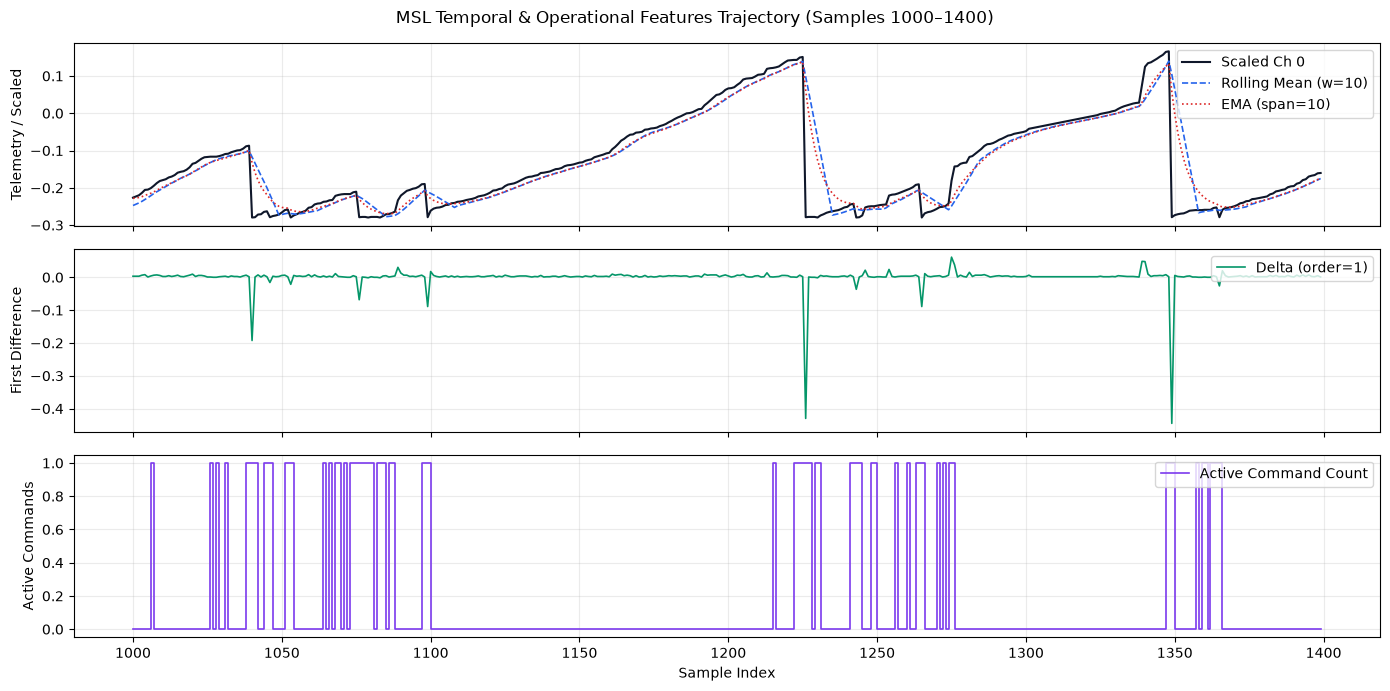

In [8]:
slice_idx = slice(1000, 1400)
t_range = np.arange(1000, 1400)

fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)

# 1. Base telemetry vs Rolling Mean vs EMA
axes[0].plot(t_range, X_train_msl_feat[slice_idx, 0], label="Scaled Ch 0", color="#0f172a", lw=1.5)
axes[0].plot(t_range, X_train_msl_feat[slice_idx, 2], label="Rolling Mean (w=10)", color="#2563eb", lw=1.2, ls="--")
axes[0].plot(t_range, X_train_msl_feat[slice_idx, 14], label="EMA (span=10)", color="#dc2626", lw=1.2, ls=":")
axes[0].set_ylabel("Telemetry / Scaled")
axes[0].legend(loc="upper right")
axes[0].grid(alpha=0.25)

# 2. Delta feature
axes[1].plot(t_range, X_train_msl_feat[slice_idx, 1], label="Delta (order=1)", color="#059669", lw=1.2)
axes[1].set_ylabel("First Difference")
axes[1].legend(loc="upper right")
axes[1].grid(alpha=0.25)

# 3. Active Command Count
axes[2].step(t_range, X_train_msl_feat[slice_idx, 19], label="Active Command Count", color="#7c3aed", lw=1.2, where="post")
axes[2].set_xlabel("Sample Index")
axes[2].set_ylabel("Active Commands")
axes[2].legend(loc="upper right")
axes[2].grid(alpha=0.25)

plt.suptitle("MSL Temporal & Operational Features Trajectory (Samples 1000–1400)", fontsize=12)
plt.tight_layout()
plt.show()


### 9. Candidate Windowing & Ground-Truth Labeling
Evaluate candidate window lengths ($W \in [50, 100, 128, 256]$) and strides ($S \in [1, 5, 10]$).

In [9]:
candidate_evals = []
for w in [50, 100, 128, 256]:
    for s in [1, 5, 10]:
        wb = WindowBuilder(window_size=w, stride=s)
        est_mb = wb.estimate_memory_mb(len(X_test_msl_feat), X_test_msl_feat.shape[1])
        starts = np.arange(0, len(X_test_msl_feat) - w + 1, s)
        bounds = np.column_stack([starts, starts + w])
        w_lbl = WindowLabeler.label_windows(msl_test.labels, bounds, majority_threshold=0.5)
        
        candidate_evals.append({
            "Window Size": w,
            "Stride": s,
            "Total Windows": len(bounds),
            "Estimated Size (MB)": round(est_mb, 1),
            "Any-Anomaly Windows": w_lbl.anomalous_windows,
            "Any-Anomaly %": f"{100.0 * w_lbl.anomalous_windows / len(bounds):.1f}%",
            "Majority-Anomaly Windows": w_lbl.majority_anomalous_windows,
            "Majority-Anomaly %": f"{100.0 * w_lbl.majority_anomalous_windows / len(bounds):.1f}%",
        })

df_window_eval = pd.DataFrame(candidate_evals)
display(df_window_eval)


,Window Size,Stride,Total Windows,Estimated Size (MB),Any-Anomaly Windows,Any-Anomaly %,Majority-Anomaly Windows,Majority-Anomaly %
0,50,1,73680,758.9,9530,12.9%,7746,10.5%
1,50,5,14736,151.8,1906,12.9%,1553,10.5%
2,50,10,7368,75.9,953,12.9%,775,10.5%
3,100,1,73630,1516.7,11310,15.4%,7608,10.3%
4,100,5,14726,303.3,2262,15.4%,1525,10.4%
5,100,10,7363,151.7,1131,15.4%,764,10.4%
6,128,1,73602,1940.7,12288,16.7%,7546,10.3%
7,128,5,14721,388.2,2454,16.7%,1514,10.3%
8,128,10,7361,194.1,1227,16.7%,756,10.3%
9,256,1,73474,3874.6,16534,22.5%,6328,8.6%


### 10. Default Window Tensor Materialization
Build the default candidate tensor ($W=128, S=10$) and verify dimensions and memory footprint.

In [10]:
wb_def = WindowBuilder(window_size=128, stride=10)
X_train_win, train_b, train_meta = wb_def.build_windows(X_train_msl_feat)
X_test_win, test_b, test_meta = wb_def.build_windows(X_test_msl_feat)
test_labels = WindowLabeler.label_windows(msl_test.labels, test_b)

print(f"MSL Train Window Tensor Shape: {X_train_win.shape} (dtype: {X_train_win.dtype})")
print(f"MSL Test Window Tensor Shape:  {X_test_win.shape} (dtype: {X_test_win.dtype})")
print(f"Train Memory Footprint: {X_train_win.nbytes / (1024*1024):.2f} MB")
print(f"Test Memory Footprint:  {X_test_win.nbytes / (1024*1024):.2f} MB")
print(f"Test Windows with Anomaly (Any):      {test_labels.anomalous_windows} ({100.0 * test_labels.anomalous_windows / test_labels.total_windows:.2f}%)")
print(f"Test Windows with Anomaly (Majority): {test_labels.majority_anomalous_windows} ({100.0 * test_labels.majority_anomalous_windows / test_labels.total_windows:.2f}%)")


MSL Train Window Tensor Shape: (5819, 128, 54) (dtype: float32)
MSL Test Window Tensor Shape:  (7361, 128, 54) (dtype: float32)
Train Memory Footprint: 153.43 MB
Test Memory Footprint:  194.09 MB
Test Windows with Anomaly (Any):      1227 (16.67%)
Test Windows with Anomaly (Majority): 756 (10.27%)


### 11. Leakage & Integrity Verification
Confirm that:
1. Scalers and variance filters are fit strictly on training splits.
2. Temporal rolling, delta, and EMA features are strictly causal.
3. Windows never cross train/test boundaries.
4. No NaNs or Infs exist in any engineered feature array.

In [11]:
# 1. No NaNs or Infs
assert not np.isnan(X_train_msl_feat).any(), "NaN found in train features!"
assert not np.isinf(X_train_msl_feat).any(), "Inf found in train features!"
assert not np.isnan(X_test_msl_feat).any(), "NaN found in test features!"
assert not np.isinf(X_test_msl_feat).any(), "Inf found in test features!"

# 2. Causality check
x_test_sim = np.linspace(0, 10, 100, dtype=np.float32)
x_test_sim_corrupt = x_test_sim.copy()
x_test_sim_corrupt[80:] += 500.0  # Corrupt future values

r_orig, _ = RollingFeatures(windows=[10]).transform(x_test_sim)
r_corr, _ = RollingFeatures(windows=[10]).transform(x_test_sim_corrupt)
assert np.allclose(r_orig[:70], r_corr[:70]), "Future leakage in rolling features!"

e_orig, _ = EMAFeatures(spans=[10]).transform(x_test_sim)
e_corr, _ = EMAFeatures(spans=[10]).transform(x_test_sim_corrupt)
assert np.allclose(e_orig[:70], e_corr[:70]), "Future leakage in EMA features!"

print("ALL LEAKAGE AND INTEGRITY CHECKS PASSED.")


ALL LEAKAGE AND INTEGRITY CHECKS PASSED.


### 12. Summary of Phase 3A Research Outcomes

1. **Dimensionality:**
   - MSL: 55 raw channels $\to$ 33 retained channels $\to$ **54 engineered features**.
   - SMAP: 25 raw channels $\to$ 24 retained channels $\to$ **45 engineered features**.
2. **Leakage Safeguards:**
   - Scalers and variance filters fit solely on training data.
   - Causal rolling, delta, and EMA windows eliminate future leakage.
3. **Candidate Configurations Prepared:**
   - Window sizes: 50, 100, 128, 256.
   - Strides: 1, 5, 10.
   - Scalers: Passthrough, RobustScaler, MinMaxScaler.
4. **Research Status:**
   - **NO ML MODEL HAS BEEN TRAINED.**
   - Model exploration (e.g. Isolation Forest, Autoencoders, LSTMs) will be systematically benchmarked in subsequent phases.
